# High-dimensional function approximation


## 1. Setup


In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import torch
from torch.utils.data import DataLoader, TensorDataset

REPO_ROOT = Path.cwd().parent
sys.path.insert(0, str(REPO_ROOT))

from utilities.residual_orponet import ResidualOrPoNet
from utilities.function_library import (
    gaussian,
    modified_rosenbrock,
    modified_zakharov,
    log_sum_exp,
    sigmoid,
    griewank,
    rastrigin,
    levy,
)

from utilities.training import Trainer


In [2]:
SEED = 17
DEVICE = torch.device("cpu")
DTYPE = torch.float32

torch.set_num_threads(1)
torch.manual_seed(SEED)


## 2. Function and domain


In [3]:
FUNCTION_NAME = "gaussian"
DIMENSION = 10  # 10, 20, 50, or 100
DEGREE = 4

functions = {
    "gaussian": (gaussian, 2),
    "modified_rosenbrock": (modified_rosenbrock, 1),
    "modified_zakharov": (modified_zakharov, 1),
    "log_sum_exp": (log_sum_exp, 2),
    "sigmoid": (sigmoid, 2),
    "griewank": (griewank, 2),
    "rastrigin": (rastrigin, 1),
    "levy": (levy, 1),
}
target_function, domain_radius = functions[FUNCTION_NAME]
print(
    f"{FUNCTION_NAME}: {DIMENSION}D, degree {DEGREE}, domain [-{domain_radius}, {domain_radius}]^{DIMENSION}"
)


gaussian: 10D, degree 4, domain [-2, 2]^10


## 3. Data


In [4]:
SAMPLES_PER_DIMENSION = 200


def sample_split(seed):
    """Sample physical coordinates with a split-specific Sobol scramble."""
    engine = torch.quasirandom.SobolEngine(DIMENSION, scramble=True, seed=seed)
    x = domain_radius * (
        2 * engine.draw(SAMPLES_PER_DIMENSION * DIMENSION, dtype=DTYPE) - 1
    )
    x = x.to(DEVICE)
    return x, target_function(x)


train_x, train_y = sample_split(6100101)
validation_x, validation_y = sample_split(6100102)
target_mean = train_y.mean()
target_std = train_y.std(unbiased=True)
if target_std <= 0:
    raise ValueError("Training targets must have nonzero variance.")
standardized_train_y = (train_y - target_mean) / target_std


## 4. Model


In [5]:
torch.manual_seed(SEED)
model = ResidualOrPoNet(
    basis_configs=[
        {"type": "chebyshev", "degree": DEGREE, "constant_channels": 2}
        for _ in range(DIMENSION)
    ],
    data_domain_lb=[-domain_radius] * DIMENSION,
    data_domain_ub=[domain_radius] * DIMENSION,
    training_domain_lb=[-1] * DIMENSION,
    training_domain_ub=[1] * DIMENSION,
    neuron_copies=1,
    normalize_basis=False,
    coeff_init_std=0.1,
    use_additive_basis_branch=True,
    gate_config=None,
    dtype=DTYPE,
).to(DEVICE)
model.apply_basis_aware_init(train_x, gain=0.1)


## 5. Training


In [6]:
ADAM_EPOCHS = 500

trainer = Trainer(
    model,
    (train_x, train_y),
    (validation_x, validation_y),
    target_stats=(target_mean, target_std),
)
adam = torch.optim.AdamW(
    model.parameters(), lr=(0.001 if DIMENSION <= 20 else 0.0001), weight_decay=1e-5
)
generator = torch.Generator().manual_seed(SEED)

train_loader = DataLoader(
    TensorDataset(train_x, standardized_train_y),
    batch_size={10: 64, 20: 128, 50: 256, 100: 512}[DIMENSION],
    shuffle=True,
    generator=generator,
)
trainer.fit(adam, epochs=ADAM_EPOCHS, batches=train_loader, log_every=100)
lbfgs = torch.optim.LBFGS(
    model.parameters(),
    lr=1.0,
    max_iter=20,
    history_size=100,
    tolerance_grad=1e-9,
    tolerance_change=1e-11,
    line_search_fn="strong_wolfe",
)
trainer.fit_lbfgs(lbfgs, steps=20, log_every=5)
trainer.restore_best()
history = trainer.history


adamw 1: validation MSE=4.453e-01


adamw 100: validation MSE=1.851e-04


adamw 200: validation MSE=8.540e-05


adamw 300: validation MSE=4.505e-05


adamw 400: validation MSE=5.779e-05


adamw 500: validation MSE=4.161e-05


lbfgs 5: validation MSE=3.021e-05


lbfgs 10: validation MSE=3.021e-05


lbfgs 15: validation MSE=3.021e-05


lbfgs 20: validation MSE=3.021e-05


## 6. Learning curves


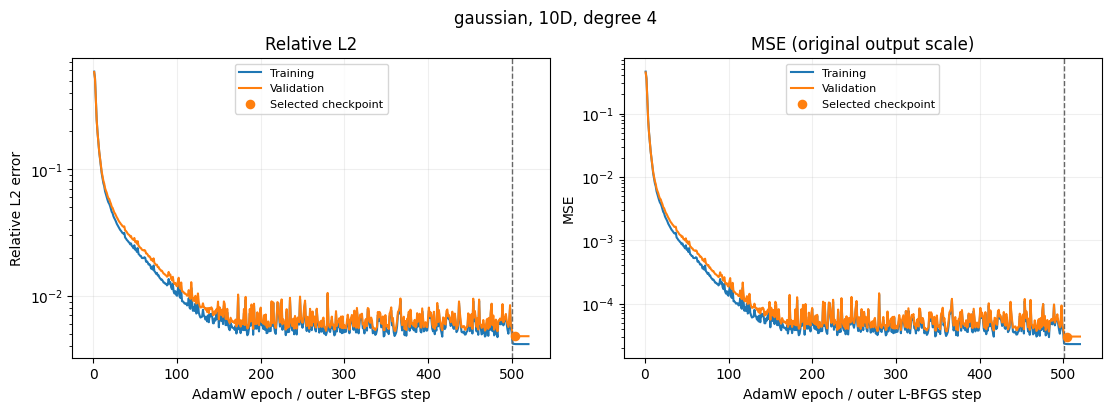

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
best_row = history.loc[history["validation_relative_l2"].idxmin()]

axes[0].semilogy(
    history["update"],
    history["train_relative_l2"].clip(lower=1e-12),
    label="Training",
    linewidth=1.5,
)
axes[0].semilogy(
    history["update"],
    history["validation_relative_l2"].clip(lower=1e-12),
    label="Validation",
    linewidth=1.5,
)
axes[0].scatter(
    best_row["update"],
    max(best_row["validation_relative_l2"], 1e-12),
    color="tab:orange",
    s=35,
    zorder=3,
    label="Selected checkpoint",
)
axes[0].set(
    title="Relative L2",
    xlabel="AdamW epoch / outer L-BFGS step",
    ylabel="Relative L2 error",
)

axes[1].semilogy(
    history["update"],
    history["train_mse"].clip(lower=1e-18),
    label="Training",
    linewidth=1.5,
)
axes[1].semilogy(
    history["update"],
    history["validation_mse"].clip(lower=1e-18),
    label="Validation",
    linewidth=1.5,
)
axes[1].scatter(
    best_row["update"],
    max(best_row["validation_mse"], 1e-18),
    color="tab:orange",
    s=35,
    zorder=3,
    label="Selected checkpoint",
)
axes[1].set(
    title="MSE (original output scale)",
    xlabel="AdamW epoch / outer L-BFGS step",
    ylabel="MSE",
)
for ax in axes:
    ax.axvline(ADAM_EPOCHS + 0.5, color="0.4", linestyle="--", linewidth=1)
    ax.grid(alpha=0.2)
    ax.legend(fontsize=8)
fig.suptitle(f"{FUNCTION_NAME}, {DIMENSION}D, degree {DEGREE}")
plt.show()


## 7. Test predictions


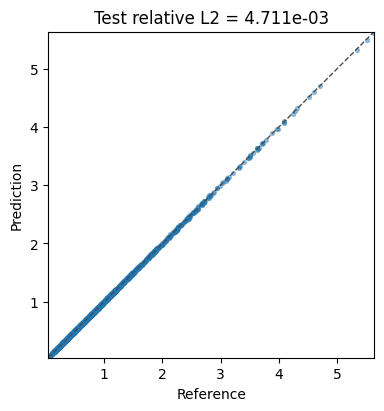

In [8]:
TEST_SEED = 6100103  # Figure 5; use 6100203 for the Figure 6 test split.

test_x, test_y = sample_split(TEST_SEED)
with torch.no_grad():
    test_prediction = model(test_x) * target_std + target_mean
    test_error = test_prediction - test_y
    test_relative_l2 = (
        torch.linalg.vector_norm(test_error) / torch.linalg.vector_norm(test_y)
    ).item()
reference = test_y[:, 0].cpu()
prediction = test_prediction[:, 0].cpu()
lower = min(reference.min().item(), prediction.min().item())
upper = max(reference.max().item(), prediction.max().item())

fig, ax = plt.subplots(figsize=(5, 4), constrained_layout=True)
ax.scatter(reference, prediction, s=8, alpha=0.4)
ax.plot([lower, upper], [lower, upper], color="0.3", linestyle="--", linewidth=1)
ax.set(
    title=f"Test relative L2 = {test_relative_l2:.3e}",
    xlabel="Reference",
    ylabel="Prediction",
    xlim=(lower, upper),
    ylim=(lower, upper),
    aspect="equal",
)
plt.show()
